# 03 · Forecasting monthly consumption

| Component | Approach |
|---|---|
| Training | January of the first year → December of the year before the test year |
| Evaluation | the last complete calendar year, as rolling **one-month-ahead** forecasts |
| Baseline | same month in the previous year (seasonal naive) |
| Comparison model | SARIMA on log kWh, order chosen by AIC on **training data only** |
| Metrics | MAE (kWh) and WAPE = Σ\|error\| / Σ actual |
| Selection | whichever approach has the lower WAPE, per development |

SARIMA is not assumed to win.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.0f}")
from nycha_energy import config, prepare, analysis, forecast, viz

In [2]:
prep = prepare.prepare()
dm = prepare.development_month(prep.records, prep.start_year, prep.end_year)
Y = prep.end_year
print(f"Train: {prep.start_year}-01 → {Y-1}-12 | Test: {Y}-01 → {Y}-12")

Train: 2019-01 → 2021-12 | Test: 2022-01 → 2022-12


## 1. Selecting five developments without looking at the test year

A development is **eligible** if, in the training period only, it reported every month, always had kWh > 0, and never
had a meter-count change. Eligible developments are ranked by training kWh (materiality), with at most two per borough.

A top-ranked development is **replaced only if its test-period data is unavailable** (fewer than 6 reported,
stable-coverage months). This checks whether test data *exists*; it never uses test *values*.

In [3]:
selection, backtest, metrics, outlook = forecast.run(dm, Y - 1, Y)
print(f"Eligible: {selection.eligible.sum()} of {len(selection)}")
selection[selection.selection_note != "Not eligible"].sort_values("candidate_rank").head(9)[
    ["development_name", "borough", "train_kwh", "candidate_rank", "selection_note"]]

Eligible: 241 of 335


,development_name,borough,train_kwh,candidate_rank,selection_note
77,CASTLE HILL,BRONX,"48,076,400",1.0000,Selected
71,WAGNER,MANHATTAN,"46,192,960",2.0000,Selected
84,GRANT,MANHATTAN,"41,405,200",3.0000,Selected
45,RAVENSWOOD,QUEENS,"41,089,600",4.0000,"Eligible, replaced: only 0 scorable test month..."
54,EDENWALD,BRONX,"40,337,840",5.0000,Selected
135,POLO GROUNDS TOWERS,MANHATTAN,"39,465,920",6.0000,"Eligible, skipped (borough cap)"
131,MITCHEL,BRONX,"37,484,000",7.0000,"Eligible, skipped (borough cap)"
50,POMONOK,QUEENS,"36,638,120",8.0000,Selected
91,LINDEN,BROOKLYN,"36,169,600",9.0000,"Eligible, not needed"


## 2. Rolling one-month-ahead backtest

In [4]:
metrics[["development_name", "borough", "sarima_order", "months_scored", "baseline_mae", "sarima_mae",
         "baseline_wape", "sarima_wape", "selected_method", "selection_reason"]]

,development_name,borough,sarima_order,months_scored,baseline_mae,sarima_mae,baseline_wape,sarima_wape,selected_method,selection_reason
0,POMONOK,QUEENS,"(0, 0, 0)x(0, 1, 0, 12)",12,"159,237","159,237",0.1600,0.1600,Seasonal naive,"Tie: AIC selected a seasonal random walk, whic..."
1,EDENWALD,BRONX,"(0, 0, 0)x(0, 1, 0, 12)",12,"76,657","76,657",0.0692,0.0692,Seasonal naive,"Tie: AIC selected a seasonal random walk, whic..."
2,WAGNER,MANHATTAN,"(0, 0, 0)x(1, 1, 0, 12)",10,"98,124","90,568",0.0762,0.0703,SARIMA,SARIMA has lower WAPE
3,CASTLE HILL,BRONX,"(1, 0, 0)x(0, 1, 0, 12)",12,"59,817","71,483",0.0449,0.0536,Seasonal naive,Seasonal naive has lower WAPE
4,GRANT,MANHATTAN,"(0, 0, 0)x(0, 1, 0, 12)",12,"100,683","100,683",0.0927,0.0927,Seasonal naive,"Tie: AIC selected a seasonal random walk, whic..."


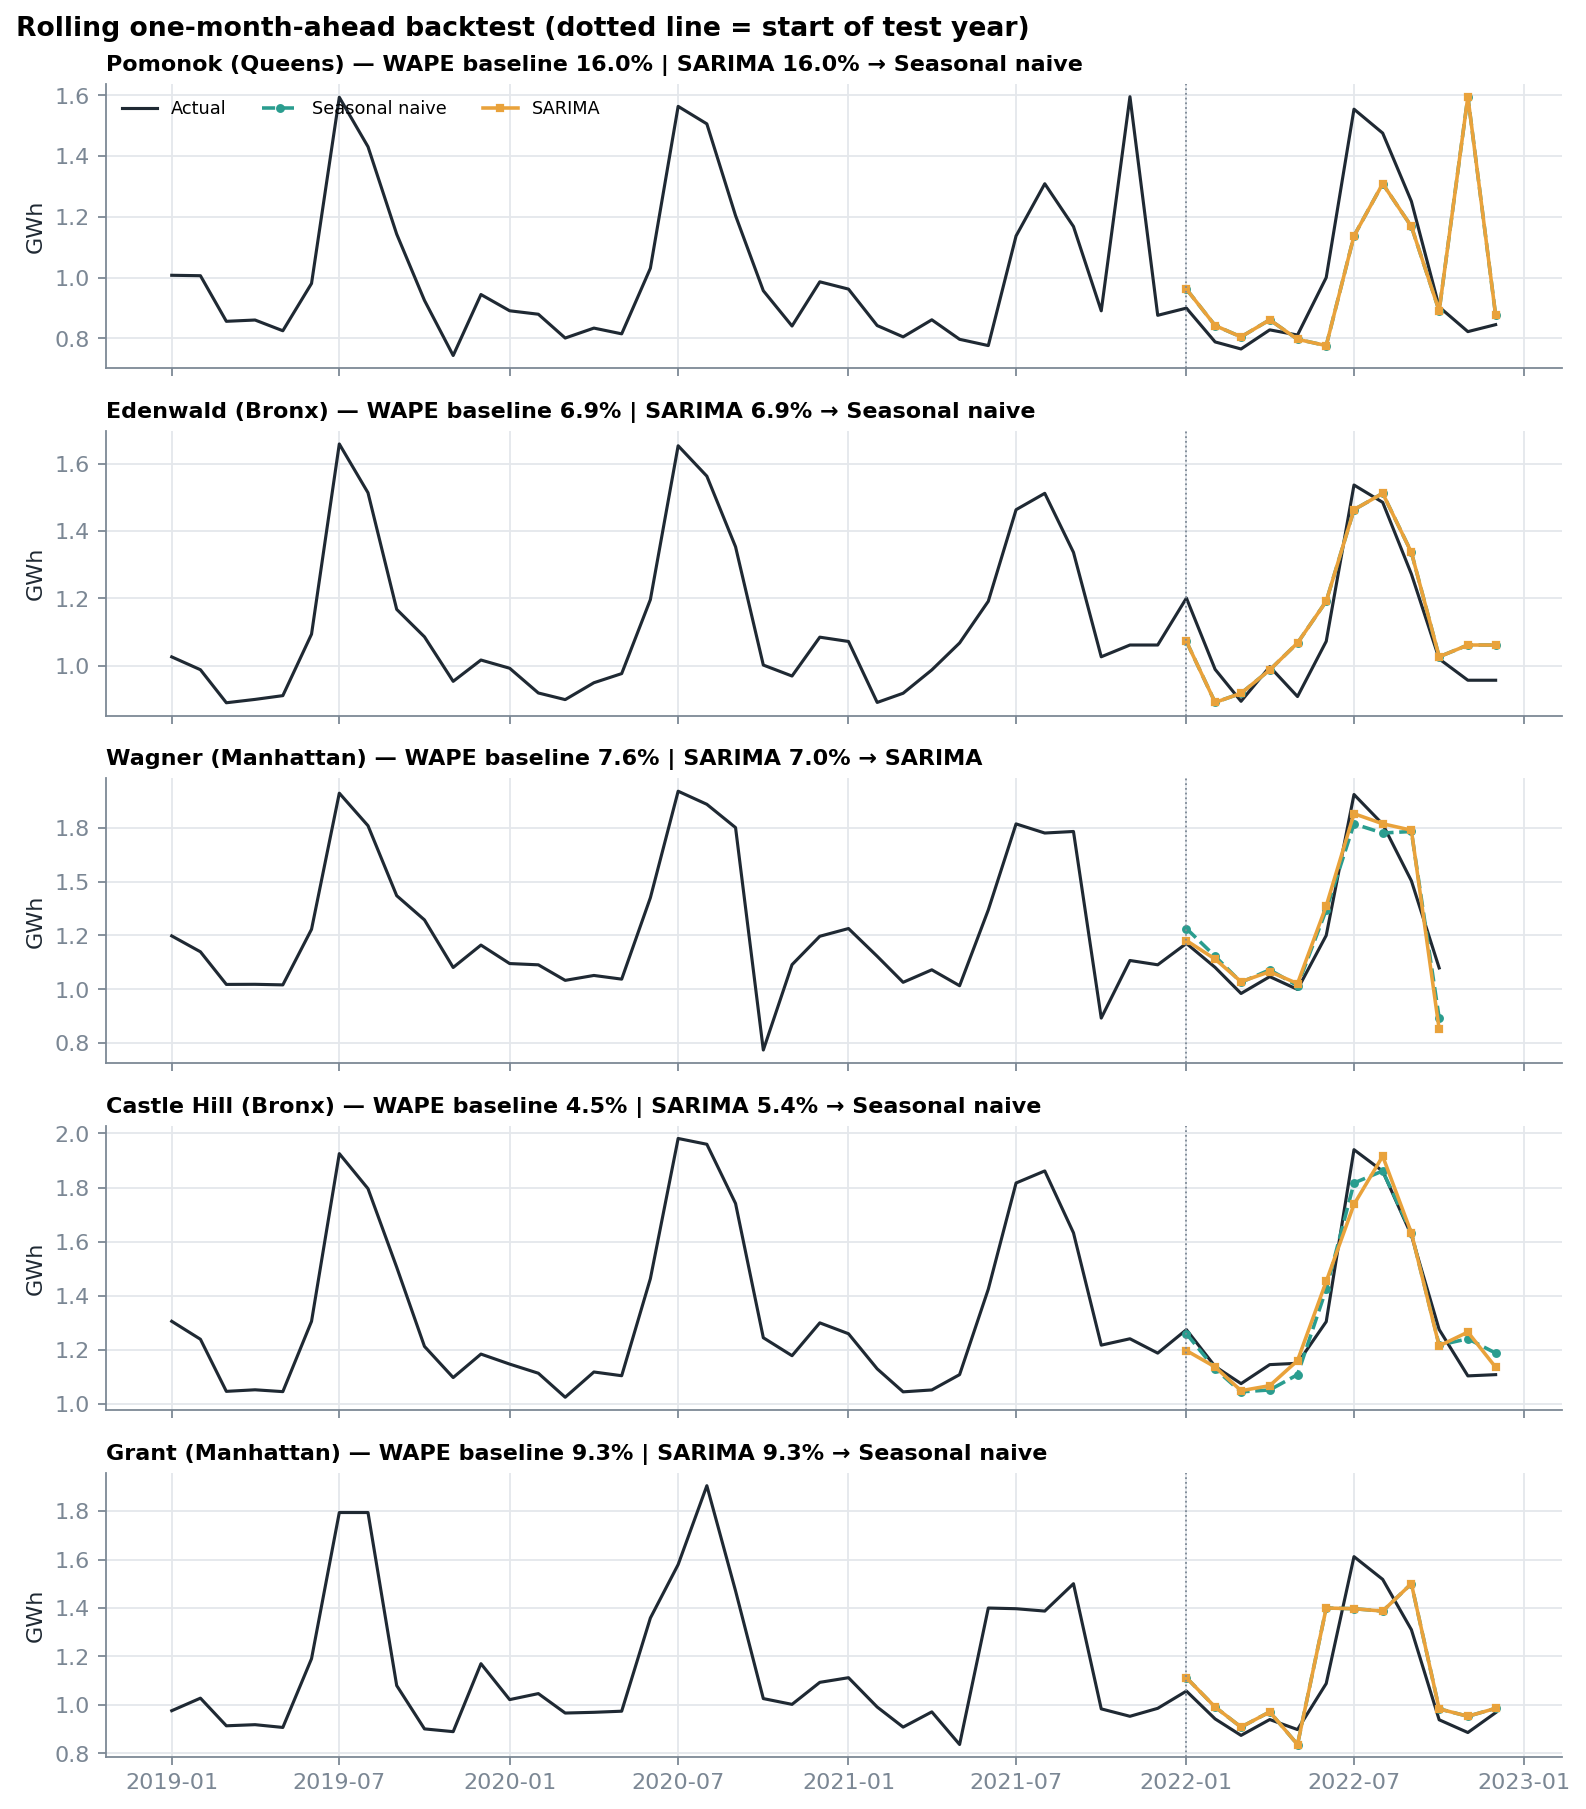

In [5]:
display(Image(str(config.FIGURES / "06_forecast_backtest.png")))

In [6]:
s = backtest[backtest.scored]
agg = {m: (s.actual - s[m]).abs().sum() / s.actual.sum() for m in ["baseline", "sarima"]}
print(f"Pooled WAPE — seasonal naive: {agg['baseline']:.1%} | SARIMA: {agg['sarima']:.1%}")

Pooled WAPE — seasonal naive: 8.5% | SARIMA: 8.6%


**Reading:** with three training years (two after seasonal differencing), AIC usually prefers a seasonal random walk,
which is the baseline itself. SARIMA adds value at only one development. The seasonal-naive baseline is hard to beat
for this kind of monthly facility load, and it is simpler to explain. Both approaches miss when the prior year contains
an anomaly, as at Pomonok in November.

## 3. Planning outlook: consumption × effective-cost scenarios

Spending = forecast kWh × an **effective-cost assumption taken from history**. This is a **planning estimate**, not a
bill forecast: it assumes today's bill structure and no billing errors.

In [7]:
scen, assumptions = forecast.spending_scenarios(outlook, dm, analysis.annual_summary(dm), Y)
display(assumptions)
scen.groupby(["development_name", "method"])[["forecast_kwh", "cost_low", "cost_base", "cost_high"]].sum()

,scenario,factor,basis
0,Low,0.7081,Lowest annual portfolio effective cost 0.1220 ...
1,Base,1.0000,Each development's same-month 2022 effective cost
2,High,1.2042,Largest annual portfolio effective-cost increa...


,,forecast_kwh,cost_low,cost_base,cost_high
development_name,method,,,,
CASTLE HILL,Seasonal naive,"16,002,200","1,958,522","2,765,699","3,330,575"
EDENWALD,Seasonal naive,"13,285,360","1,491,886","2,106,746","2,537,036"
GRANT,Seasonal naive,"13,034,000","1,630,421","2,302,377","2,772,622"
POMONOK,Seasonal naive,"11,942,080","1,506,356","2,127,179","2,561,642"
WAGNER,SARIMA,"15,168,876","1,944,189","2,745,460","3,306,202"


In [8]:
tot = scen[["forecast_kwh", "cost_low", "cost_base", "cost_high"]].sum()
print(f"Five developments, next 12 months: {tot.forecast_kwh/1e6:,.1f} GWh; "
      f"spend ${tot.cost_low/1e6:,.1f}M (low) / ${tot.cost_base/1e6:,.1f}M (base) / ${tot.cost_high/1e6:,.1f}M (high)")

Five developments, next 12 months: 69.4 GWh; spend $8.5M (low) / $12.0M (base) / $14.5M (high)


## Limitations
- Only three training years, one of them 2020, which was shaped by the pandemic. Longer histories from a current download will change the order selection.
- No weather, occupancy or equipment drivers are available in this dataset, so the models are purely univariate.
- Effective-cost scenarios bracket historical movements. They do not model supply-price contracts or tariff filings.